Classes: ['Ankle-boot', 'Bag', 'Coat', 'Dress', 'Pullover', 'Sandal', 'Shirt', 'Sneaker', 'T-shirt-top', 'Trouser']
Dataset Shape: (500, 224, 224, 3)
Epoch 1/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 66s 1s/step - accuracy: 0.2500 - loss: 2.4061 - val_accuracy: 0.4200 - val_loss: 1.5749
Epoch 2/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 69s 1s/step - accuracy: 0.3925 - loss: 1.5504 - val_accuracy: 0.5500 - val_loss: 1.2321
Epoch 3/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 72s 1s/step - accuracy: 0.4525 - loss: 1.4260 - val_accuracy: 0.7000 - val_loss: 0.9979
Epoch 4/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.5025 - loss: 1.2929 - val_accuracy: 0.7100 - val_loss: 1.0177
Epoch 5/5
50/50 ━━━━━━━━━━━━━━━━━━━━ 65s 1s/step - accuracy: 0.5375 - loss: 1.2259 - val_accuracy: 0.6800 - val_loss: 0.9864
4/4 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.6800 - loss: 0.9864

Loss before Fine Tuning: 0.9863893389701843
Accuracy before Fine Tuning: 0.6800000071525574
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 691ms/step


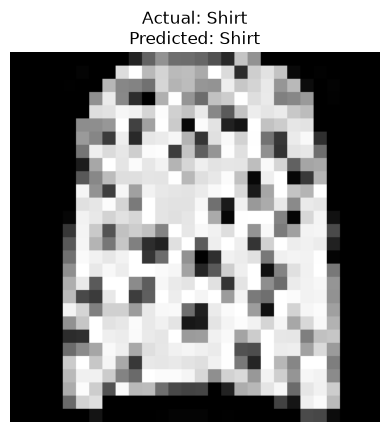

Epoch 1/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.5125 - loss: 1.1818 - val_accuracy: 0.7500 - val_loss: 0.8034
Epoch 2/2
50/50 ━━━━━━━━━━━━━━━━━━━━ 79s 2s/step - accuracy: 0.5475 - loss: 1.1065 - val_accuracy: 0.7100 - val_loss: 0.7716
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 3s/step - accuracy: 0.7100 - loss: 0.7716

Loss after Fine Tuning: 0.7715555429458618
Accuracy after Fine Tuning: 0.7099999785423279


In [1]:
# ============================================================
# FASHION MNIST IMAGE CLASSIFICATION USING VGG16
# TRANSFER LEARNING
# ============================================================

import numpy as np
import os
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Flatten, Dense, Dropout
from tensorflow.keras.applications import VGG16
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 1. DATASET PATH
# ------------------------------------------------------------

dataset_path = r"D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\Object Detection\fashion mnist"

weight_path = r"D:\Downloads\LP IV Updated Datasets\LP IV Updated Datasets\Object Detection\vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"


# ------------------------------------------------------------
# 2. GET CLASS FOLDERS
# ------------------------------------------------------------

classes = [
    folder for folder in os.listdir(dataset_path)
    if folder != "train"
]

classes = sorted(classes)

print("Classes:", classes)


# ------------------------------------------------------------
# 3. LOAD IMAGES
# ------------------------------------------------------------

X = []
y = []

for label, class_name in enumerate(classes):

    class_path = os.path.join(dataset_path, class_name)

    # Take only 50 images from each class
    images = os.listdir(class_path)[:50]

    for image in images:

        image_path = os.path.join(class_path, image)

        try:
            # Resize image for VGG16
            img = load_img(
                image_path,
                target_size=(224, 224),
                color_mode="rgb"
            )

            # Convert image into array
            img = img_to_array(img)

            X.append(img)
            y.append(label)

        except:
            pass


# ------------------------------------------------------------
# 4. CONVERT TO NUMPY ARRAYS
# ------------------------------------------------------------

X = np.array(X)
y = np.array(y)

print("Dataset Shape:", X.shape)


# ------------------------------------------------------------
# 5. NORMALIZE IMAGES
# ------------------------------------------------------------

X = X / 255.0


# ------------------------------------------------------------
# 6. SPLIT DATA
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ------------------------------------------------------------
# 7. LOAD PRETRAINED VGG16 MODEL
# ------------------------------------------------------------

base_model = VGG16(
    weights=None,
    include_top=False,
    input_shape=(224, 224, 3)
)

# Load offline pretrained weights
base_model.load_weights(weight_path)


# ------------------------------------------------------------
# 8. FREEZE VGG16 BASE LAYERS
# ------------------------------------------------------------

base_model.trainable = False


# ------------------------------------------------------------
# 9. ADD CUSTOM CLASSIFICATION LAYERS
# ------------------------------------------------------------

model = Sequential([
    base_model,
    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.5),
    Dense(len(classes), activation="softmax")
])


# ------------------------------------------------------------
# 10. COMPILE MODEL
# ------------------------------------------------------------

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ------------------------------------------------------------
# 11. TRAIN MODEL
# ------------------------------------------------------------

model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=8,
    validation_data=(X_test, y_test)
)


# ------------------------------------------------------------
# 12. COMPUTE LOSS AND EVALUATE
# ------------------------------------------------------------

loss, accuracy = model.evaluate(X_test, y_test)

print("\nLoss before Fine Tuning:", loss)
print("Accuracy before Fine Tuning:", accuracy)


# ------------------------------------------------------------
# 13. VISUALIZE PREDICTION
# ------------------------------------------------------------

index = 0

prediction = model.predict(X_test[index:index+1])

predicted_class = np.argmax(prediction)

plt.imshow(X_test[index])

plt.title(
    "Actual: " + classes[y_test[index]] +
    "\nPredicted: " + classes[predicted_class]
)

plt.axis("off")
plt.show()


# ------------------------------------------------------------
# 14. FINE TUNING
# ------------------------------------------------------------

# Unfreeze VGG16
base_model.trainable = True

# Freeze all layers except the last 4 layers
for layer in base_model.layers[:-4]:
    layer.trainable = False


# Compile again with a smaller learning rate
model.compile(
    optimizer=Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ------------------------------------------------------------
# 15. TRAIN AGAIN
# ------------------------------------------------------------

model.fit(
    X_train,
    y_train,
    epochs=2,
    batch_size=8,
    validation_data=(X_test, y_test)
)


# ------------------------------------------------------------
# 16. FINAL EVALUATION
# ------------------------------------------------------------

loss, accuracy = model.evaluate(X_test, y_test)

print("\nLoss after Fine Tuning:", loss)
print("Accuracy after Fine Tuning:", accuracy)